# 03 — Model experimentation and comparison

Five models from five algorithm families, all trained and evaluated by the same harness
(`pathsnap/models/evaluate.py`, run with `python -m pathsnap.models.train`).

**Protocol**
- Data: reliable rows of `data/processed/<partition>_candidates.parquet`; X = 16 features, y = 1 if the candidate is the true arc.
- Cross-validation: 5-fold `GroupKFold` over the **80 train trips**, grouped by `trip_id` (no trip in both fit and validation).
- Development test: refit on all train, evaluate on the **10 student_test trips**.
- Untuned (default-style) configurations here; Bayesian optimisation of the chosen model is a separate step.
- Evaluator-test data is not used.

**Metrics**: macro F1, precision, recall, log loss (per candidate row, threshold 0.5); observation-level Top-1 accuracy
(per GPS point, the highest-scoring candidate is the true arc); route continuity (consecutive predicted arcs identical
or connected); training and inference time.

In [1]:
# --- setup: find the repo, check data and trained models ---
import sys, pathlib, subprocess, json
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "pathsnap" / "config.py").exists():
    raise RuntimeError("Run this notebook from inside the cloned repo (its notebooks/ folder).")
sys.path.insert(0, str(ROOT))
from pathsnap.reproduce import ensure_processed, models_ready
from pathsnap.models.registry import RECOMMENDED
ensure_processed()                # builds data/processed/* if missing (~1 min)

# Trained models are not in git (weights are large). Missing ones are trained here when this
# flag is True; the recommended five take ~30-40 min on an 8-core laptop.
TRAIN_IF_MISSING = True
missing = models_ready(RECOMMENDED)
if missing and TRAIN_IF_MISSING:
    print("training missing models:", missing)
    subprocess.run([sys.executable, "-m", "pathsnap.models.train", *missing], cwd=ROOT, check=True)
elif missing:
    raise RuntimeError(f"Models not trained yet: {missing}. Run: python -m pathsnap.models.train")
print("models OK:", RECOMMENDED)

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from pathsnap.config import RESULTS_DIR, ARTIFACTS_DIR, SEED
from pathsnap.features.candidates import FEATURE_COLUMNS
from pathsnap.models.evaluate import load_candidates, subsample_points, evaluate
from pathsnap.models.ranker import predict_p
from pathsnap.models.registry import REGISTRY
from pathsnap.viz import model_plots

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
MD = RESULTS_DIR / "models"

raw data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/Student folder  {'train': 80, 'student_test': 10}
processed data OK: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/data/processed
models OK: ['logreg', 'knn', 'rf', 'lgbm', 'mlp']


## 1. Configurations

In [2]:
comp = pd.read_csv(MD / "comparison.csv")
models = comp["model"].tolist()
meta = {m: json.loads((MD / m / "metrics.json").read_text()) for m in models}   # saved with each run
pd.DataFrame([{"model": m, "family": meta[m]["family"], "configuration": meta[m]["description"],
               "train_fraction": meta[m]["train_fraction"], "notes": " ".join(meta[m]["notes"])}
              for m in models])

,model,family,configuration,train_fraction,notes
0,lgbm_rank,Boosting (learning to rank),"LGBMRanker(lambdarank, 400 trees, lr=0.05, num...",1.0,Trained on each GPS observation's candidates a...
1,xgb_rank,Boosting (learning to rank),"XGBRanker(rank:ndcg, 400 trees, lr=0.05, max_d...",1.0,Trained on each GPS observation's candidates a...
2,xgb_tuned,Boosting,"XGBoost tuned by Optuna TPE: n_estimators=750,...",1.0,best of 50 Optuna trials (objective: CV top-1)
3,rf,Ensemble (bagging),"RandomForest(200 trees, min_samples_leaf=5, ma...",1.0,
4,lgbm,Boosting,"LightGBM(400 trees, lr=0.05, num_leaves=63)",1.0,
5,xgb,Boosting,"XGBoost(400 trees, lr=0.05, max_depth=6, hist)",1.0,
6,dtree,Tree-based,"DecisionTree(max_depth=12, min_samples_leaf=20)",1.0,
7,mlp,Neural network,"StandardScaler + MLP(64-32, ReLU, Adam, early ...",1.0,early_stopping holds out a random 10% of train...
8,knn,Instance-based,"StandardScaler + KNN(k=25, distance-weighted),...",0.1,KNN prediction cost grows with training size; ...
9,logreg,Linear / probabilistic,"StandardScaler + LogisticRegression(C=1.0, lbfgs)",1.0,


## 2. Consolidated comparison

In [3]:
table = comp[["model", "family", "cv_macro_f1", "cv_macro_f1_std", "cv_top1", "cv_row_accuracy",
              "test_top1", "test_row_accuracy", "test_macro_f1",
              "test_precision_macro", "test_recall_macro", "test_log_loss", "test_route_continuity",
              "fit_seconds", "inference_ms_per_1000_points"]].sort_values("cv_macro_f1", ascending=False)
table.round(4)

,model,family,cv_macro_f1,cv_macro_f1_std,cv_top1,cv_row_accuracy,test_top1,test_row_accuracy,test_macro_f1,test_precision_macro,test_recall_macro,test_log_loss,test_route_continuity,fit_seconds,inference_ms_per_1000_points
0,lgbm_rank,Boosting (learning to rank),0.9472,0.0191,0.9041,0.9748,0.9022,0.9765,0.9469,0.9574,0.9370,0.0569,0.9558,29.4674,73.2580
1,xgb_rank,Boosting (learning to rank),0.9462,0.0187,0.9023,0.9743,0.9113,0.9783,0.9509,0.9626,0.9400,0.0564,0.9579,40.4338,25.5364
2,xgb_tuned,Boosting,0.9449,0.0180,0.9040,0.9737,0.9086,0.9765,0.9473,0.9542,0.9406,0.0612,0.9588,38.3263,35.0802
3,rf,Ensemble (bagging),0.9442,0.0172,0.9004,0.9734,0.9002,0.9751,0.9436,0.9549,0.9331,0.0627,0.9537,144.0836,26.5997
4,lgbm,Boosting,0.9438,0.0178,0.9015,0.9731,0.9028,0.9752,0.9445,0.9516,0.9376,0.0650,0.9563,24.4600,113.6769
5,xgb,Boosting,0.9437,0.0176,0.9019,0.9731,0.9048,0.9756,0.9451,0.9535,0.9372,0.0618,0.9573,19.0551,10.2273
6,dtree,Tree-based,0.9392,0.0182,0.8963,0.9709,0.8943,0.9732,0.9395,0.9489,0.9306,0.0745,0.9475,47.2679,1.4841
7,mlp,Neural network,0.9389,0.0191,0.8936,0.9708,0.8930,0.9722,0.9384,0.9401,0.9368,0.0748,0.9538,398.5355,5.2464
8,knn,Instance-based,0.9220,0.0143,0.8724,0.9633,0.8666,0.9649,0.9197,0.9356,0.9054,0.1126,0.9563,0.1052,1205.1185
9,logreg,Linear / probabilistic,0.9181,0.0112,0.8781,0.9610,0.8691,0.9611,0.9126,0.9202,0.9054,0.0995,0.9324,8.0262,2.0382


## 3. Stability across folds

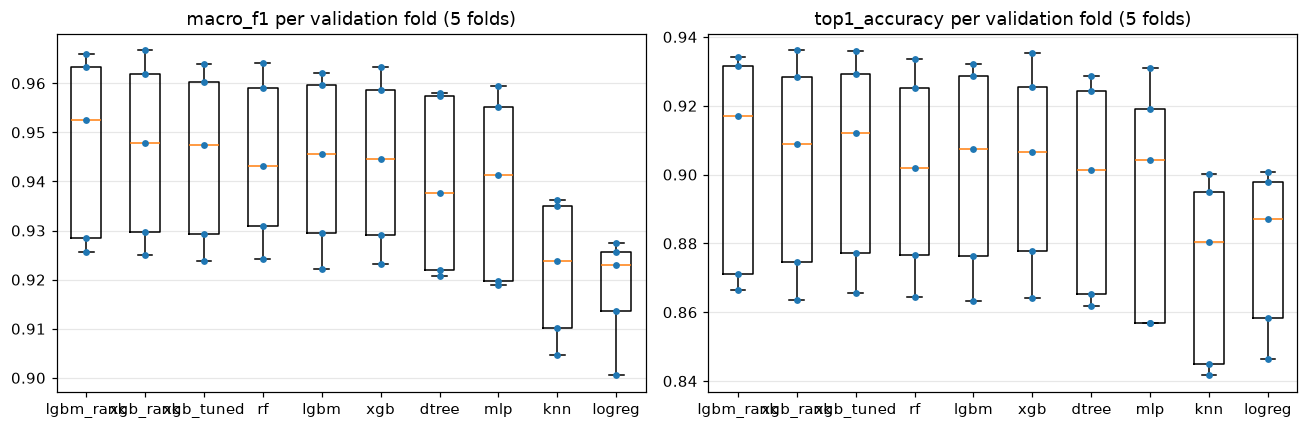

model,dtree,knn,lgbm,lgbm_rank,logreg,mlp,rf,xgb,xgb_rank,xgb_tuned
fold,,,,,,,,,,
0,0.8619,0.8416,0.8633,0.8665,0.8464,0.8570,0.8645,0.8641,0.8636,0.8655
1,0.9242,0.8949,0.9286,0.9315,0.8980,0.9190,0.9252,0.9255,0.9283,0.9292
2,0.9285,0.9002,0.9321,0.9343,0.9009,0.9309,0.9337,0.9353,0.9361,0.9359
3,0.8654,0.8449,0.8762,0.8713,0.8582,0.8569,0.8767,0.8778,0.8745,0.8772
4,0.9014,0.8804,0.9075,0.9171,0.8871,0.9043,0.9019,0.9067,0.9088,0.9120


In [4]:
folds = pd.concat([pd.read_csv(MD / m / "cv_folds.csv").assign(model=m) for m in models])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = table["model"].tolist()
for ax, metric in zip(axes, ["macro_f1", "top1_accuracy"]):
    data = [folds.loc[folds.model == m, metric] for m in order]
    ax.boxplot(data, tick_labels=order)
    for i, d in enumerate(data, start=1):
        ax.scatter(np.full(len(d), i), d, s=12, color="#1f77b4", zorder=3)
    ax.set_title(f"{metric} per validation fold (5 folds)"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
folds.pivot_table(index="fold", columns="model", values="top1_accuracy").round(4)

Fold-to-fold variation is larger than most gaps between models: some trips are much harder than others, so the mean alone is not enough to rank models.

## 4. Comparison plots (generated from the saved results by `pathsnap/viz/model_plots.py`)

plots -> /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/pathsnap/results/models/plots


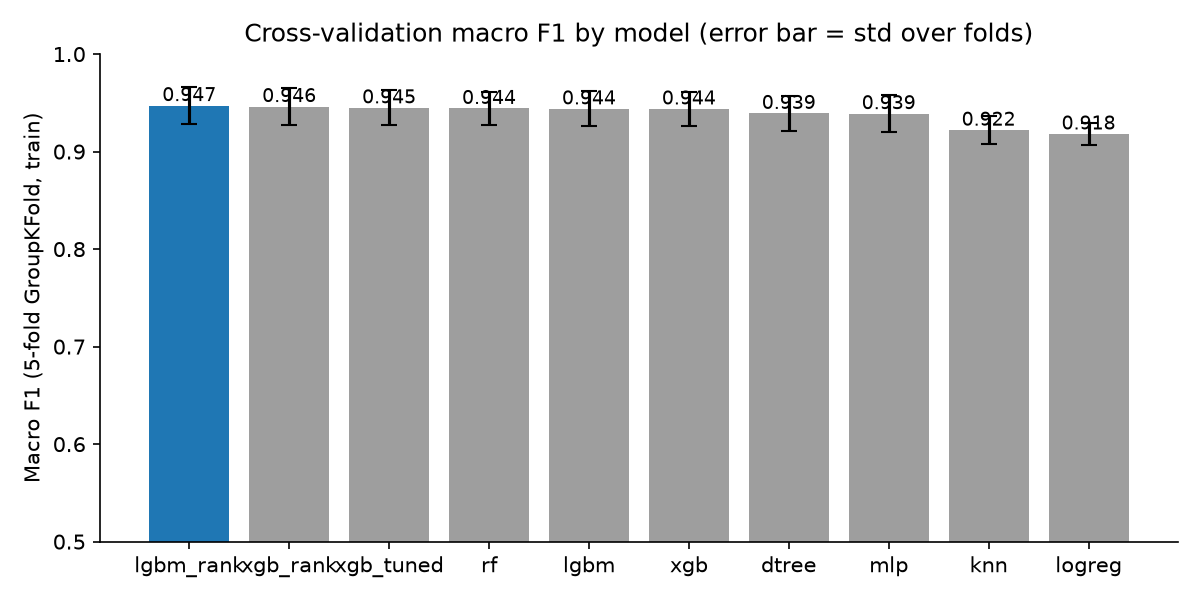

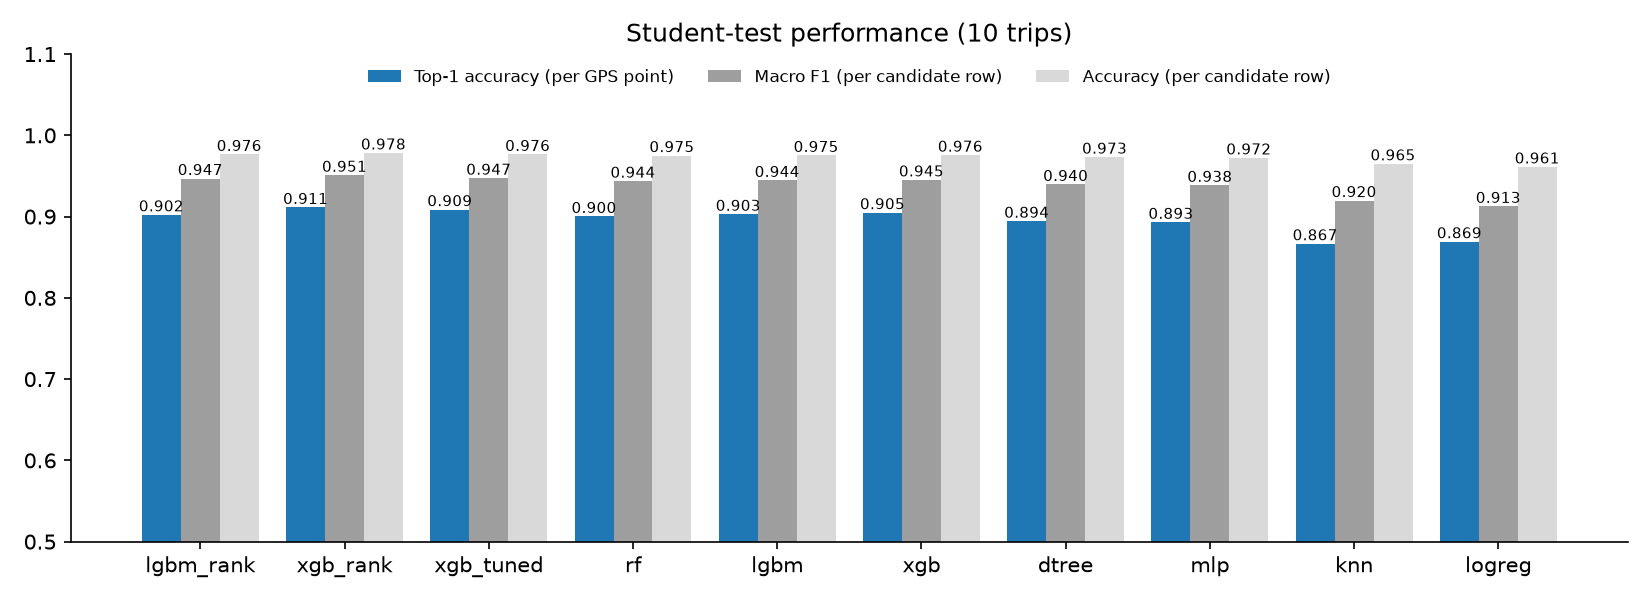

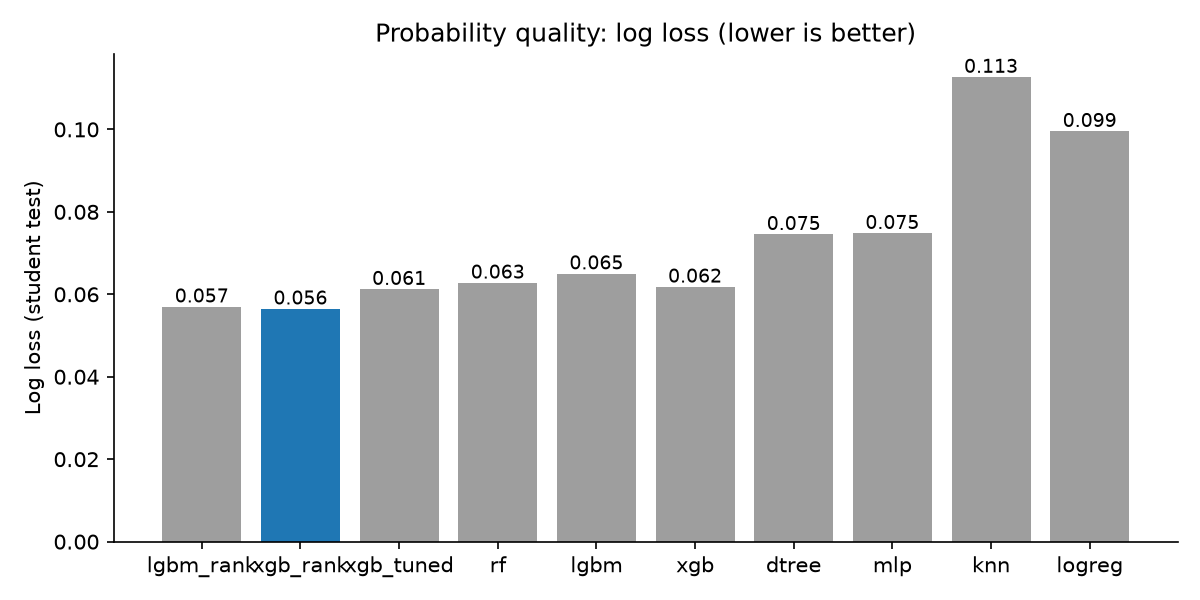

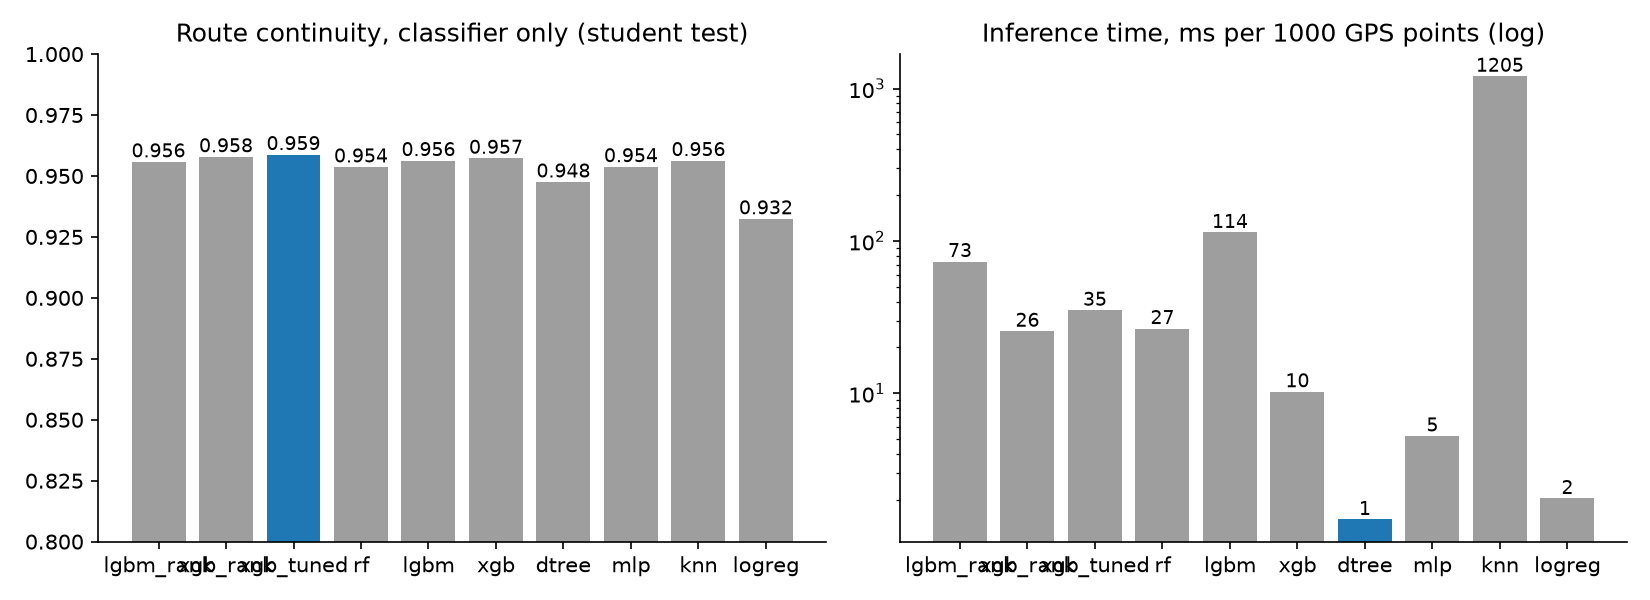

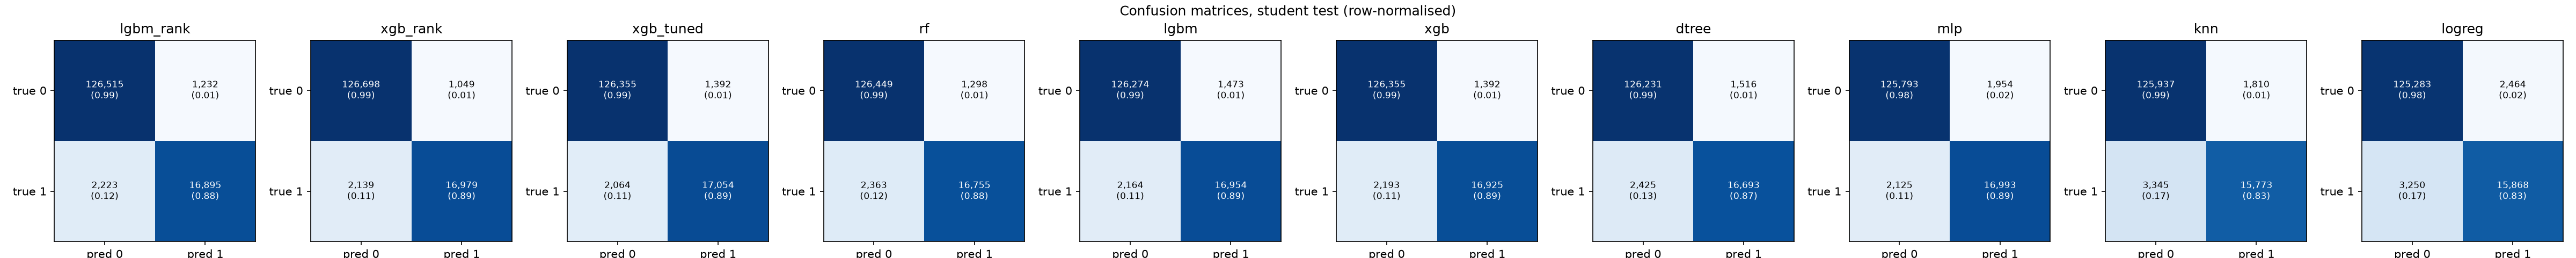

In [5]:
model_plots.main()
for f in ["cv_macro_f1.png", "student_test_top1_f1.png", "log_loss.png", "continuity_inference.png",
          "confusion_matrices.png"]:
    display(Image(filename=str(MD / "plots" / f)))

## 5. Overfitting / underfitting check

Each final model (fitted on all train) is scored on a 20% sample of train GPS points and compared with its cross-validation and student-test scores. A large train-vs-validation gap indicates overfitting; low scores everywhere indicate underfitting.

In [6]:
train = load_candidates("train")
train_s = subsample_points(train, 0.2, seed=SEED)
rows = []
for m in models:
    est = joblib.load(ARTIFACTS_DIR / "models" / f"{m}.joblib")
    proba = predict_p(est, train_s)
    tr = evaluate(train_s, proba)
    r = comp.set_index("model").loc[m]
    rows.append({"model": m, "train_top1": tr["top1_accuracy"], "cv_top1": r.cv_top1, "test_top1": r.test_top1,
                 "train_macro_f1": tr["macro_f1"], "cv_macro_f1": r.cv_macro_f1,
                 "train_log_loss": tr["log_loss"], "cv_log_loss": r.cv_log_loss})
fit = pd.DataFrame(rows)
fit["top1_gap_train_minus_cv"] = fit.train_top1 - fit.cv_top1
fit.round(4)

,model,train_top1,cv_top1,test_top1,train_macro_f1,cv_macro_f1,train_log_loss,cv_log_loss,top1_gap_train_minus_cv
0,lgbm_rank,0.9631,0.9041,0.9022,0.9781,0.9472,0.0367,0.0643,0.0589
1,xgb_rank,0.9425,0.9023,0.9113,0.9671,0.9462,0.0471,0.0646,0.0402
2,xgb_tuned,0.9537,0.9040,0.9086,0.9729,0.9449,0.0366,0.0690,0.0497
3,rf,0.9581,0.9004,0.9002,0.9734,0.9442,0.0377,0.0698,0.0577
4,lgbm,0.9438,0.9015,0.9028,0.9668,0.9438,0.0417,0.0731,0.0422
5,xgb,0.9315,0.9019,0.9048,0.9611,0.9437,0.0497,0.0694,0.0296
6,dtree,0.9150,0.8963,0.8943,0.9505,0.9392,0.0596,0.0906,0.0187
7,mlp,0.9310,0.8936,0.8930,0.9602,0.9389,0.0519,0.0816,0.0374
8,knn,0.9359,0.8724,0.8666,0.9638,0.9220,0.0568,0.1296,0.0635
9,logreg,0.8799,0.8781,0.8691,0.9194,0.9181,0.1072,0.1082,0.0017


## 6. Training history (only models that train by epochs)

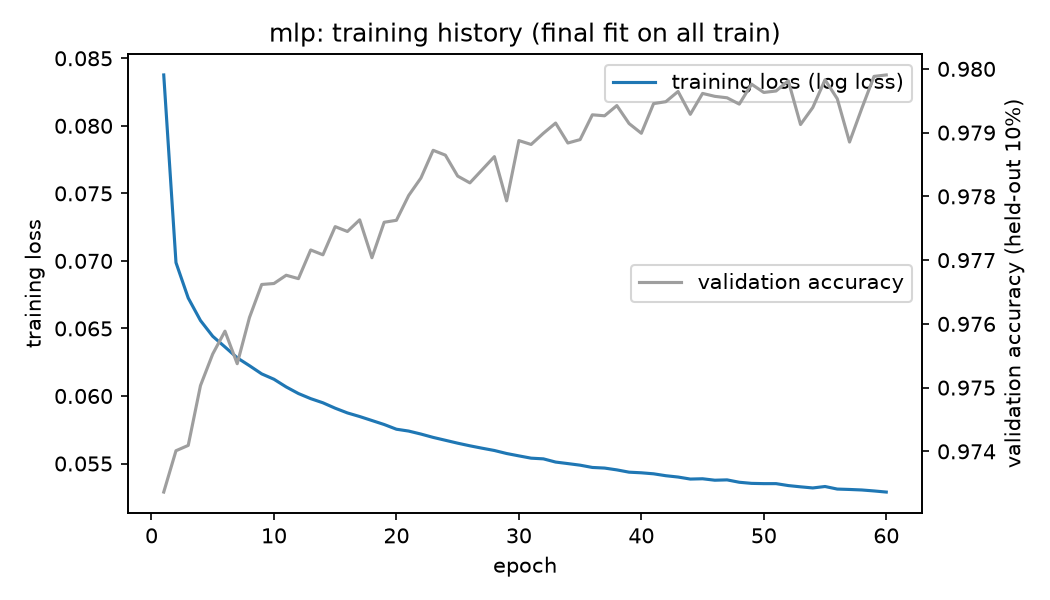

mlp: 60 epochs, final training loss 0.0529
models without epoch-wise history (no curve drawn): ['lgbm_rank', 'xgb_rank', 'xgb_tuned', 'rf', 'lgbm', 'xgb', 'dtree', 'knn', 'logreg']


In [7]:
curves = [m for m in models if (MD / m / "loss_curve.csv").exists()]
for m in curves:
    display(Image(filename=str(MD / "plots" / f"{m}_training_curve.png")))
    c = pd.read_csv(MD / m / "loss_curve.csv")
    print(f"{m}: {len(c)} epochs, final training loss {c.train_loss.iloc[-1]:.4f}")
print("models without epoch-wise history (no curve drawn):", [m for m in models if m not in curves])

## 7. Feature importance (tree models)

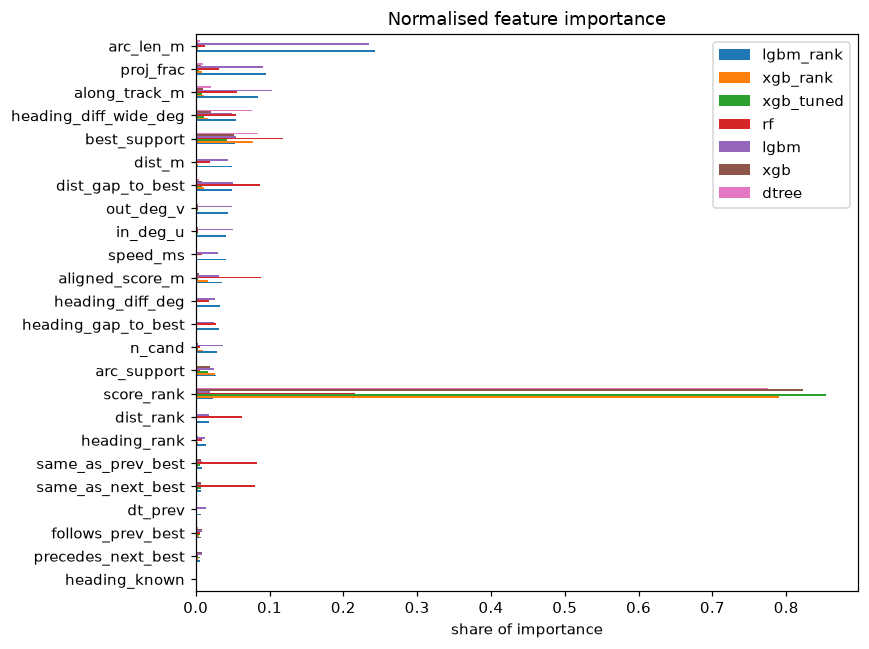

,lgbm_rank,xgb_rank,xgb_tuned,rf,lgbm,xgb,dtree
arc_len_m,0.2431,0.0026,0.0031,0.0128,0.2349,0.0031,0.0059
proj_frac,0.0956,0.0084,0.0047,0.0311,0.0914,0.0068,0.0102
along_track_m,0.0844,0.0110,0.0085,0.0555,0.1030,0.0104,0.0210
heading_diff_wide_deg,0.0544,0.0167,0.0112,0.0543,0.0493,0.0203,0.0769
best_support,0.0526,0.0774,0.0425,0.1186,0.0545,0.0521,0.0839
dist_m,0.0492,0.0027,0.0018,0.0199,0.0442,0.0018,0.0016
dist_gap_to_best,0.0490,0.0115,0.0083,0.0877,0.0502,0.0086,0.0049
out_deg_v,0.0439,0.0021,0.0030,0.0030,0.0497,0.0028,0.0014
in_deg_u,0.0409,0.0019,0.0030,0.0031,0.0505,0.0028,0.0010
speed_ms,0.0408,0.0006,0.0011,0.0085,0.0300,0.0006,0.0009


In [8]:
imp = {}
for m in models:
    est = joblib.load(ARTIFACTS_DIR / "models" / f"{m}.joblib")
    final = est[-1] if hasattr(est, "steps") else est
    if hasattr(final, "feature_importances_"):
        v = np.asarray(final.feature_importances_, dtype=float)
        imp[m] = v / v.sum()
if imp:
    imp_df = pd.DataFrame(imp, index=FEATURE_COLUMNS).sort_values(list(imp)[0], ascending=True)
    imp_df.plot.barh(figsize=(8, 6)); plt.title("Normalised feature importance"); plt.xlabel("share of importance")
    plt.tight_layout(); plt.show()
    display(imp_df.sort_values(list(imp)[0], ascending=False).round(4))

## 8. Ranking for model selection

Primary metric: **observation-level Top-1 accuracy** (the task is choosing the right arc per GPS point).
Secondary: **log loss**, because the HMM uses the predicted probabilities as emission scores, so calibration matters.
Also considered: stability across folds, inference speed (the API must answer quickly), and model complexity.

In [9]:
rank = table.set_index("model")[["cv_top1", "test_top1", "cv_macro_f1", "test_log_loss",
                                  "inference_ms_per_1000_points"]].copy()
rank["cv_top1_std"] = folds.groupby("model")["top1_accuracy"].std()
rank.sort_values(["cv_top1"], ascending=False).round(4)

,cv_top1,test_top1,cv_macro_f1,test_log_loss,inference_ms_per_1000_points,cv_top1_std
model,,,,,,
lgbm_rank,0.9041,0.9022,0.9472,0.0569,73.2580,0.0329
xgb_tuned,0.9040,0.9086,0.9449,0.0612,35.0802,0.0313
xgb_rank,0.9023,0.9113,0.9462,0.0564,25.5364,0.0321
xgb,0.9019,0.9048,0.9437,0.0618,10.2273,0.0305
lgbm,0.9015,0.9028,0.9438,0.0650,113.6769,0.0308
rf,0.9004,0.9002,0.9442,0.0627,26.5997,0.0299
dtree,0.8963,0.8943,0.9392,0.0745,1.4841,0.0316
mlp,0.8936,0.8930,0.9389,0.0748,5.2464,0.0348
logreg,0.8781,0.8691,0.9181,0.0995,2.0382,0.0245
